# Evolução Arquitetural de Deep Learning na Marcação a Mercado
**Uma Abordagem Walk-Forward para Títulos do Tesouro Direto**

* **Ativo Alvo:** NTN-B Principal (Tesouro IPCA+ 2035)
* **Variável Preditiva:** Taxa de Compra Manhã (% a.a.)
* **Período Histórico:** Janeiro/2020 a Dezembro/2026 (625 pregões)
* **Objetivo:** Simular um motor de negociação preditivo livre de viés de antecipação (*Data Leakage*), utilizando Redes Neurais e Filtros de Quartis.

### Roteiro do Experimento

| Etapa | Descrição |
| :--- | :--- |
| **1** | Carregamento e Ingestão de Arquivos Históricos (`.xls`) |
| **2** | Engenharia de Features e Escalonamento Dinâmico (Z-Score) |
| **3** | Construção da Fábrica de IA (LSTM, GRU e Transformers) |
| **4** | Simulação Temporal: Validação *Walk-Forward* (Janela Deslizante) |
| **5** | Avaliação Estatística e Geração do Sinal Combinado (Compra/Venda) |

In [1]:
# 0. Instalação e Importação de Bibliotecas Essenciais
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (LSTM, GRU, Dense, Dropout, Input,
                                     LayerNormalization, MultiHeadAttention,
                                     GlobalAveragePooling1D)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam

# Configurações de Reprodutibilidade e Limpeza Visual
warnings.filterwarnings('ignore')
tf.random.set_seed(42)
np.random.seed(42)

print(f"TensorFlow Version: {tf.__version__}")
print("Bibliotecas importadas com sucesso e ambiente configurado.")

TensorFlow Version: 2.21.0
Bibliotecas importadas com sucesso e ambiente configurado.


### Etapa 1: Ingestão e Tratamento da Base de Dados

Os dados brutos do Tesouro Nacional são disponibilizados em arquivos anuais fragmentados no formato legado `.xls`, frequentemente contendo cabeçalhos inconsistentes.

A classe `TesouroDataFetcher` foi projetada para automatizar o processo de Extração, Transformação e Carregamento (ETL). O algoritmo:
1. Itera sobre os dicionários de arquivos de 2020 a 2026.
2. Extrai a aba específica do ativo desejado (ex: `NTN-B Princ 150535`).
3. Ignora ruídos de cabeçalho (`header=1`).
4. Preenche lacunas de feriados bancários propagando a última taxa válida (*Forward Fill*), simulando o estado real do mercado em dias não úteis.

In [2]:
# 1. Extrator de Dados (Data Fetcher)
class TesouroDataFetcher:
    def __init__(self, dicionario_arquivos, aba_alvo='NTN-B Princ 150535'):
        """
        Inicializa o extrator adaptado para a fragmentação anual do Tesouro Direto.
        """
        self.dicionario_arquivos = dicionario_arquivos
        self.aba_alvo = aba_alvo

    def processar_base(self):
        lista_dataframes = []
        print("Iniciando a unificação da base de dados do Tesouro Direto...")

        for ano, caminho in self.dicionario_arquivos.items():
            print(f" > Processando ano {ano}: {caminho}")
            try:
                # O parâmetro engine='xlrd' é obrigatório para arquivos legados do Tesouro
                df_ano = pd.read_excel(caminho, sheet_name=self.aba_alvo, header=1, engine='xlrd')
                lista_dataframes.append(df_ano)
            except Exception as e:
                print(f"   [ERRO] Falha ao processar o arquivo de {ano}: {e}")

        if not lista_dataframes:
            raise ValueError("Nenhum dado foi carregado. Verifique os caminhos e abas alvo.")

        # Unificação e Padronização
        df_raw = pd.concat(lista_dataframes, ignore_index=True)

        colunas_map = {
            'Dia': 'Data',
            'Data Venda': 'Data',
            'Taxa Compra Manhã': 'Taxa_Compra',
            'Taxa Venda Manhã': 'Taxa_Venda',
            'PU Compra Manhã': 'PU_Compra'
        }
        df_raw.rename(columns=colunas_map, inplace=True)

        # Tratamento Cronológico
        df_raw['Data'] = pd.to_datetime(df_raw['Data'], errors='coerce')
        df_raw.dropna(subset=['Data'], inplace=True)
        df_raw = df_raw.sort_values(by='Data').reset_index(drop=True)

        colunas_finais = ['Data', 'Taxa_Compra', 'Taxa_Venda', 'PU_Compra']
        colunas_finais = [col for col in colunas_finais if col in df_raw.columns]
        df_clean = df_raw[colunas_finais].copy()

        # Propagação do último valor válido para feriados (Forward Fill)
        df_clean.ffill(inplace=True)

        print("-" * 50)
        print(f"Base UNIFICADA com sucesso! Total de pregões: {len(df_clean)}")
        print(f"Período contínuo: {df_clean['Data'].min().strftime('%d/%m/%Y')} a {df_clean['Data'].max().strftime('%d/%m/%Y')}")
        print("-" * 50)

        return df_clean

### Etapa 2: Pré-processamento e Escalonamento Dinâmico (Z-Score)

O treinamento eficiente de Redes Neurais em séries temporais exige que os dados de entrada possuam a mesma escala. O módulo `DataProcessor` aplica a padronização estatística ($Z-Score$) para redimensionar a distribuição dos dados, garantindo média zero ($\mu = 0$) e variância unitária ($\sigma = 1$).

A transformação matemática é definida por:

$$z = \frac{x - \mu}{\sigma}$$

**Proteção contra Data Leakage:** O cálculo de $\mu$ e $\sigma$ é restrito **exclusivamente à janela de treinamento**. O conjunto de teste é escalonado utilizando os parâmetros aprendidos no treino, prevenindo que informações do futuro influenciem a etapa de aprendizado do modelo. O módulo também é responsável por estruturar os dados em matrizes tridimensionais `(amostras, lookback, features)` exigidas pelas camadas recorrentes do TensorFlow.

In [3]:
# 2. Processador de Dados (Escalonamento Dinâmico e Janelamento)
class DataProcessor:
    def __init__(self, target_column='Taxa_Compra', date_column='Data', lookback=20):
        """
        Inicializa o processador responsável pela normalização segura e criação de janelas.
        :param lookback: Número de dias no passado usados para prever o dia seguinte.
        """
        self.target_column = target_column
        self.date_column = date_column
        self.lookback = lookback
        self.scaler = StandardScaler()

    def prepare_walk_forward_window(self, train_df, test_df):
        """
        Aplica o escalonamento fit_transform APENAS no treino, e transform no teste.
        """
        train_data = train_df[[self.target_column]].values
        test_data = test_df[[self.target_column]].values

        # Isolamento estatístico: aprendendo média e variância apenas no passado
        train_scaled = self.scaler.fit_transform(train_data)
        test_scaled = self.scaler.transform(test_data)

        X_train, y_train = self._create_sequences(train_scaled)
        X_test, y_test = self._create_sequences(test_scaled)

        # Reshape para (Amostras, Timesteps, Features)
        X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
        X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

        return X_train, y_train, X_test, y_test

    def _create_sequences(self, data):
        """
        Desloca a série temporal para criar os pares de entrada (X) e rótulo alvo (y).
        """
        X, y = [], []
        for i in range(self.lookback, len(data)):
            X.append(data[i-self.lookback:i, 0])
            y.append(data[i, 0])
        return np.array(X), np.array(y)

    def inverse_transform(self, scaled_data):
        """
        Reverte a taxa para a sua dimensão percentual original para facilitar a leitura.
        """
        scaled_data_reshaped = np.array(scaled_data).reshape(-1, 1)
        return self.scaler.inverse_transform(scaled_data_reshaped).flatten()

### Etapa 3: Fábrica de Modelos de Deep Learning (ModelFactory)

Este módulo atua como uma interface centralizada para compilar diferentes topologias preditivas. Para garantir a robustez em um ambiente volátil e não-estacionário, os modelos foram parametrizados com técnicas de regularização:

1. **Redes LSTM (Long Short-Term Memory):** Padrão sólido em memórias sequenciais.
2. **Redes GRU (Gated Recurrent Unit):** Otimização em velocidade, operando com arquitetura unificada de portões de atualização.
3. **Transformers:** A evolução não-sequencial. Utiliza o Mecanismo de Atenção Múltipla (*Multi-Head Attention*) para capturar correlações globais ao longo de toda a janela de *lookback* simultaneamente.

Todos os modelos utilizam *Dropout* ($30\%$) e Regularização $L2$ (penalidade sobre o peso dos *kernels*) para evitar o sobreajuste (*overfitting*), otimizados pelo algoritmo iterativo.

In [4]:
# 3. Fábrica de Arquiteturas Neurais
class ModelFactory:
    def __init__(self, input_shape):
        """
        :param input_shape: Formato de entrada tridimensional esperado pelas camadas do Keras.
        """
        self.input_shape = input_shape
        # Taxa restritiva para evitar instabilidade na descida do gradiente
        self.learning_rate = 0.001

    def build_lstm(self, units=50, dropout_rate=0.3, l2_reg=0.01):
        model = Sequential([
            Input(shape=self.input_shape),
            LSTM(units, return_sequences=False, kernel_regularizer=l2(l2_reg)),
            Dropout(dropout_rate),
            Dense(25, activation='relu'),
            Dense(1, activation='linear')
        ])
        model.compile(optimizer=Adam(learning_rate=self.learning_rate), loss='mse')
        return model

    def build_gru(self, units=50, dropout_rate=0.3, l2_reg=0.01):
        model = Sequential([
            Input(shape=self.input_shape),
            GRU(units, return_sequences=False, kernel_regularizer=l2(l2_reg)),
            Dropout(dropout_rate),
            Dense(25, activation='relu'),
            Dense(1, activation='linear')
        ])
        model.compile(optimizer=Adam(learning_rate=self.learning_rate), loss='mse')
        return model

    def build_transformer(self, head_size=64, num_heads=4, ff_dim=64, num_blocks=2, dropout_rate=0.3):
        inputs = Input(shape=self.input_shape)
        x = inputs

        for _ in range(num_blocks):
            # Mecanismo de Autoatenção
            attention_output = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout_rate)(x, x)
            x = LayerNormalization(epsilon=1e-6)(x + attention_output)

            # Feed Forward
            ff_output = Dense(ff_dim, activation="relu")(x)
            ff_output = Dropout(dropout_rate)(ff_output)
            ff_output = Dense(self.input_shape[-1])(ff_output)
            x = LayerNormalization(epsilon=1e-6)(x + ff_output)

        x = GlobalAveragePooling1D(data_format="channels_last")(x)
        x = Dense(32, activation="relu")(x)
        x = Dropout(dropout_rate)(x)
        outputs = Dense(1, activation="linear")(x)

        model = Model(inputs, outputs)
        model.compile(optimizer=Adam(learning_rate=self.learning_rate), loss='mse')
        return model

### Etapa 2: Pré-processamento e Escalonamento Dinâmico (Z-Score)

O treino eficiente de Redes Neuronais em séries temporais exige que os tensores de entrada possuam a mesma escala. O módulo `DataProcessor` aplica a padronização estatística ($Z-Score$) para redimensionar a distribuição dos dados, garantindo média zero ($\mu = 0$) e variância unitária ($\sigma = 1$).

A transformação matemática é definida por:

$$z = \frac{x - \mu}{\sigma}$$

**Proteção contra Data Leakage (Fuga de Dados):** O cálculo de $\mu$ e $\sigma$ é restrito **exclusivamente à janela de treino**. O conjunto de teste é escalonado utilizando os parâmetros aprendidos no treino, prevenindo rigorosamente que informações do futuro influenciem a etapa de aprendizagem do modelo. O módulo também é responsável por estruturar os dados em matrizes tridimensionais `(amostras, lookback, features)` exigidas pelas camadas recorrentes do TensorFlow.

In [5]:
# 2. Processador de Dados (Escalonamento Dinâmico e Janelamento)
class DataProcessor:
    def __init__(self, target_column='Taxa_Compra', date_column='Data', lookback=20):
        """
        Inicializa o processador responsável pela normalização segura e criação de janelas.
        :param lookback: Número de dias no passado usados para prever o dia seguinte.
        """
        self.target_column = target_column
        self.date_column = date_column
        self.lookback = lookback
        self.scaler = StandardScaler()

    def prepare_walk_forward_window(self, train_df, test_df):
        """
        Aplica o escalonamento fit_transform APENAS no treino, e transform no teste.
        """
        train_data = train_df[[self.target_column]].values
        test_data = test_df[[self.target_column]].values

        # Isolamento estatístico: a aprender a média e variância apenas no passado
        train_scaled = self.scaler.fit_transform(train_data)
        test_scaled = self.scaler.transform(test_data)

        X_train, y_train = self._create_sequences(train_scaled)
        X_test, y_test = self._create_sequences(test_scaled)

        # Reshape para (Amostras, Timesteps, Features)
        X_train = np.reshape(X_train, (X_train.shape[0], X_train.shape[1], 1))
        X_test = np.reshape(X_test, (X_test.shape[0], X_test.shape[1], 1))

        return X_train, y_train, X_test, y_test

    def _create_sequences(self, data):
        """
        Desloca a série temporal para criar os pares de entrada (X) e rótulo alvo (y).
        """
        X, y = [], []
        for i in range(self.lookback, len(data)):
            X.append(data[i-self.lookback:i, 0])
            y.append(data[i, 0])
        return np.array(X), np.array(y)

    def inverse_transform(self, scaled_data):
        """
        Reverte a taxa para a sua dimensão percentual original para facilitar a leitura.
        """
        scaled_data_reshaped = np.array(scaled_data).reshape(-1, 1)
        return self.scaler.inverse_transform(scaled_data_reshaped).flatten()

### Etapa 3: Fábrica de Modelos de Deep Learning (ModelFactory)

Este módulo atua como uma interface centralizada para compilar diferentes topologias preditivas. Para garantir a robustez num ambiente volátil e não-estacionário, os modelos foram parametrizados com técnicas de regularização ativa:

1. **Redes LSTM (Long Short-Term Memory):** Padrão ouro em memórias sequenciais.
2. **Redes GRU (Gated Recurrent Unit):** Otimização em velocidade, operando com arquitetura unificada de portões de atualização.
3. **Transformers:** Estado da arte não-sequencial. Utiliza o Mecanismo de Atenção Múltipla (*Multi-Head Attention*) para capturar correlações globais ao longo de toda a janela de *lookback* simultaneamente.

Todos os modelos utilizam *Dropout* ($30\%$) e Regularização $L2$ (penalidade sobre o peso dos *kernels*) para evitar o sobreajuste (*overfitting*), otimizados pelo algoritmo iterativo.

In [6]:
# 3. Fábrica de Arquiteturas Neuronais
class ModelFactory:
    def __init__(self, input_shape):
        """
        :param input_shape: Formato de entrada tridimensional esperado pelas camadas do Keras.
        """
        self.input_shape = input_shape
        # Taxa restritiva para evitar instabilidade na descida do gradiente
        self.learning_rate = 0.001

    def build_lstm(self, units=50, dropout_rate=0.3, l2_reg=0.01):
        model = Sequential([
            Input(shape=self.input_shape),
            LSTM(units, return_sequences=False, kernel_regularizer=l2(l2_reg)),
            Dropout(dropout_rate),
            Dense(25, activation='relu'),
            Dense(1, activation='linear')
        ])
        model.compile(optimizer=Adam(learning_rate=self.learning_rate), loss='mse')
        return model

    def build_gru(self, units=50, dropout_rate=0.3, l2_reg=0.01):
        model = Sequential([
            Input(shape=self.input_shape),
            GRU(units, return_sequences=False, kernel_regularizer=l2(l2_reg)),
            Dropout(dropout_rate),
            Dense(25, activation='relu'),
            Dense(1, activation='linear')
        ])
        model.compile(optimizer=Adam(learning_rate=self.learning_rate), loss='mse')
        return model

    def build_transformer(self, head_size=64, num_heads=4, ff_dim=64, num_blocks=2, dropout_rate=0.3):
        inputs = Input(shape=self.input_shape)
        x = inputs

        for _ in range(num_blocks):
            # Mecanismo de Autoatenção
            attention_output = MultiHeadAttention(key_dim=head_size, num_heads=num_heads, dropout=dropout_rate)(x, x)
            x = LayerNormalization(epsilon=1e-6)(x + attention_output)

            # Feed Forward
            ff_output = Dense(ff_dim, activation="relu")(x)
            ff_output = Dropout(dropout_rate)(ff_output)
            ff_output = Dense(self.input_shape[-1])(ff_output)
            x = LayerNormalization(epsilon=1e-6)(x + ff_output)

        x = GlobalAveragePooling1D(data_format="channels_last")(x)
        x = Dense(32, activation="relu")(x)
        x = Dropout(dropout_rate)(x)
        outputs = Dense(1, activation="linear")(x)

        model = Model(inputs, outputs)
        model.compile(optimizer=Adam(learning_rate=self.learning_rate), loss='mse')
        return model

### Etapa 4: Motor de Simulação Temporal (Walk-Forward Engine)

Para simular fidedignamente o ambiente operacional de uma mesa de operações e evitar o viés de antecipação (*look-ahead bias*), implementou-se a validação em janela deslizante.

O motor `WalkForwardEngine` opera sob a seguinte lógica sequencial:
1. Treina a rede neuronal num bloco histórico contínuo (ex: 500 pregões).
2. Prevê de forma perfeitamente cega o passo de teste subsequente (ex: 20 pregões).
3. Armazena as previsões, avança a janela no tempo (descartando os dados mais antigos e absorvendo os novos) e limpa a memória gráfica (GPU/RAM) para instanciar um modelo virgem.

In [7]:
# 4. Motor Walk-Forward (A Máquina do Tempo)
class WalkForwardEngine:
    def __init__(self, data_processor, model_factory, train_window_size=500, test_step_size=20):
        self.processor = data_processor
        self.factory = model_factory
        self.train_window_size = train_window_size
        self.test_step_size = test_step_size

    def run_simulation(self, df, model_type='gru', epochs=50, batch_size=32):
        print(f"--- Iniciando Walk-Forward Validation ({model_type.upper()}) ---")
        resultados_finais = []
        total_dias = len(df)

        for start_test_idx in range(self.train_window_size, total_dias, self.test_step_size):
            # Limpa a sessão do Keras a cada iteração para evitar vazamento de memória e sobrecarga
            tf.keras.backend.clear_session()

            end_test_idx = min(start_test_idx + self.test_step_size, total_dias)

            # Recortes de Tempo (Treino e Teste)
            train_df = df.iloc[start_test_idx - self.train_window_size : start_test_idx].copy()
            test_df = df.iloc[start_test_idx : end_test_idx].copy()

            lookback_df = df.iloc[start_test_idx - self.processor.lookback : start_test_idx].copy()
            test_df_with_lookback = pd.concat([lookback_df, test_df])

            X_train, y_train, X_test, y_test = self.processor.prepare_walk_forward_window(train_df, test_df_with_lookback)

            if model_type == 'lstm': model = self.factory.build_lstm()
            elif model_type == 'gru': model = self.factory.build_gru()
            elif model_type == 'transformer': model = self.factory.build_transformer()

            data_inicio = train_df['Data'].min().strftime('%d/%m/%y')
            data_fim_treino = train_df['Data'].max().strftime('%d/%m/%y')
            data_fim_teste = test_df['Data'].max().strftime('%d/%m/%y')

            print(f"[{data_inicio} a {data_fim_treino}] Treinando... Prevendo até: {data_fim_teste}")

            model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, verbose=0)
            y_pred_scaled = model.predict(X_test, verbose=0)

            y_pred_real = self.processor.inverse_transform(y_pred_scaled)
            y_test_real = self.processor.inverse_transform(y_test)

            for i in range(len(test_df)):
                resultados_finais.append({
                    'Data': test_df.iloc[i]['Data'],
                    'Taxa_Real': y_test_real[i],
                    'Taxa_Prevista': y_pred_real[i]
                })

        df_resultados = pd.DataFrame(resultados_finais)
        df_resultados.set_index('Data', inplace=True)
        return df_resultados

### Etapa 5: Avaliação Estatística e Sinal Combinado (O Juiz)

Este módulo atua como o árbitro final da pesquisa. Ele quantifica o erro preditivo da rede neural utilizando métricas absolutas e relativas (**RMSE, MAE e MAPE**).

Além da validação matemática, o `Evaluator` implementa o **Sinal Combinado**: um filtro tático baseado em Quartis Históricos ($Q_1$ e $Q_3$) extraídos de uma janela móvel de 60 pregões. A plotagem inclui zonas demarcadas graficamente para comprovar que o algoritmo não efetua operações impulsivas em mercados lateralizados.

In [8]:
# 5. Avaliador, Gestão de Risco e Plotagem Académica
class Evaluator:
    def __init__(self, df_resultados, df_historico_completo, window_size_quartil=60):
        self.df = df_resultados.copy()
        self.df_historico = df_historico_completo.copy()
        self.df_historico.set_index('Data', inplace=True)
        self.window_size_quartil = window_size_quartil

    def calculate_metrics(self):
        y_true = self.df['Taxa_Real'].values
        y_pred = self.df['Taxa_Prevista'].values

        rmse = np.sqrt(mean_squared_error(y_true, y_pred))
        mae = mean_absolute_error(y_true, y_pred)
        mape = np.mean(np.abs((y_true - y_pred) / np.where(y_true == 0, 1e-10, y_true))) * 100

        print("\n" + "="*50)
        print("Tabela Resumo de Métricas Preditivas:")
        print(f"{'Métrica':<35} | {'Valor Observado':>12}")
        print("-" * 50)
        print(f"{'RMSE (Raiz do Erro Quadrático)':<35} | {rmse:>12.6f}")
        print(f"{'MAE (Erro Absoluto Médio)':<35} | {mae:>12.6f}")
        print(f"{'MAPE (Erro Percentual Absoluto)':<35} | {mape:>11.2f}%")
        print("="*50)

        return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape}

    def evaluate_combined_signal(self):
        sinais, historico_q1, historico_q3 = [], [], []

        for data, row in self.df.iterrows():
            taxa_atual = row['Taxa_Real']
            taxa_prevista = row['Taxa_Prevista']

            historico_janela = self.df_historico.loc[:data].iloc[-self.window_size_quartil - 1 : -1]

            if historico_janela.empty:
                sinais.append("Dados Insuficientes"); historico_q1.append(np.nan); historico_q3.append(np.nan)
                continue

            q1 = historico_janela['Taxa_Compra'].quantile(0.25)
            q3 = historico_janela['Taxa_Compra'].quantile(0.75)

            historico_q1.append(q1)
            historico_q3.append(q3)

            sinal_neural_compra = taxa_prevista > q3
            sinal_estatistico_compra = taxa_atual > q3

            if sinal_neural_compra and sinal_estatistico_compra:
                sinais.append("COMPRA EXCELENTE")
            elif taxa_prevista < q1 and taxa_atual < q1:
                sinais.append("VENDA")
            else:
                sinais.append("NEUTRO / AGUARDAR")

        self.df['Sinal_Marcacao'] = sinais
        self.df['Q1_Historico'] = historico_q1
        self.df['Q3_Historico'] = historico_q3
        return self.df

    def plot_predictions(self, model_name, asset_name):
        plt.figure(figsize=(14, 6))
        plt.plot(self.df.index, self.df['Taxa_Real'], label='Taxa Real (Alvo)', color='#2c3e50', lw=2)
        plt.plot(self.df.index, self.df['Taxa_Prevista'], label=f'Previsão ({model_name})', color='#e74c3c', linestyle='--', lw=1.5)

        # Bandas de Quartis (Zonas de Decisão)
        plt.plot(self.df.index, self.df['Q3_Historico'], label='Limite Superior (Q3)', color='#27ae60', linestyle=':', lw=1)
        plt.plot(self.df.index, self.df['Q1_Historico'], label='Limite Inferior (Q1)', color='#8e44ad', linestyle=':', lw=1)

        plt.fill_between(self.df.index, self.df['Q1_Historico'], self.df['Q3_Historico'], color='gray', alpha=0.08, label='Zona de Lateralização')

        plt.title(f'Desempenho Preditivo e Zonas de Decisão - {asset_name}\nValidação Contínua Walk-Forward', fontweight='bold', fontsize=14)
        plt.ylabel('Taxa de Compra (% a.a.)', fontsize=12)
        plt.xlabel('Data do Pregão', fontsize=12)
        plt.legend(loc='lower left', bbox_to_anchor=(0.0, 1.01), ncol=5, borderaxespad=0, frameon=False)
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

    def export_tcc_tables(self):
        df_alertas = self.df[self.df['Sinal_Marcacao'] != 'NEUTRO / AGUARDAR'].copy()
        print("\n" + "-" * 60)
        print("DADOS EXTREMOS EXTRAÍDOS PARA TABELAS DO CAPÍTULO 4 (TCC):")
        print("-" * 60)
        if df_alertas.empty:
            print("Nenhum sinal extremo gerado neste período.")
        else:
            colunas = ['Taxa_Real', 'Taxa_Prevista', 'Q3_Historico', 'Q1_Historico', 'Sinal_Marcacao']
            print(df_alertas[colunas].tail(10).round(4))

### Bloco Principal de Execução (O Laboratório)

Esta célula integra todos os módulos concebidos anteriormente. Altere as variáveis `MEMORIA_TREINO` e `PASSO_TESTE` para simular diferentes condições de stresse de mercado.

Iniciando a unificação da base de dados do Tesouro Direto...
 > Processando ano 2020: NTN-B_Principal_2020.xls
 > Processando ano 2021: NTN-B_Principal_2021.xls
 > Processando ano 2022: NTN-B_Principal_2022.xls
 > Processando ano 2023: NTN-B_Principal_2023.xls
 > Processando ano 2024: NTN-B_Principal_2024.xls
 > Processando ano 2025: NTN-B_Principal_2025.xls
 > Processando ano 2026: NTN-B_Principal_2026.xls
--------------------------------------------------
Base UNIFICADA com sucesso! Total de pregões: 625
Período contínuo: 04/01/2020 a 05/12/2026
--------------------------------------------------
--- Iniciando Walk-Forward Validation (GRU) ---
[04/01/20 a 10/02/25] Treinando... Prevendo até: 03/05/25
[08/03/20 a 03/05/25] Treinando... Prevendo até: 07/07/25
[02/06/20 a 07/07/25] Treinando... Prevendo até: 01/10/25
[07/08/20 a 01/10/25] Treinando... Prevendo até: 03/12/25
[11/10/20 a 03/12/25] Treinando... Prevendo até: 05/05/26


[09/01/21 a 05/05/26] Treinando... Prevendo até: 03/11/26


[03/04/21 a 03/11/26] Treinando... Prevendo até: 05/12/26

Tabela Resumo de Métricas Preditivas:
Métrica                             | Valor Observado
--------------------------------------------------
RMSE (Raiz do Erro Quadrático)      |     0.001868
MAE (Erro Absoluto Médio)           |     0.001517
MAPE (Erro Percentual Absoluto)     |        2.04%


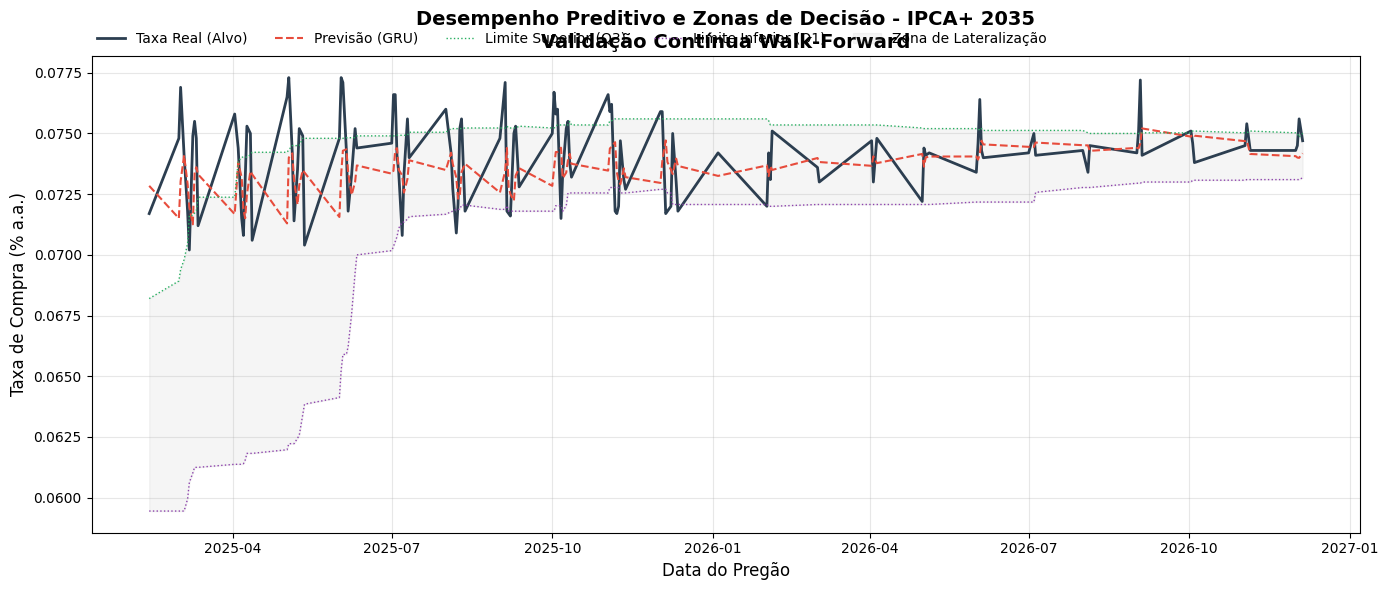


------------------------------------------------------------
DADOS EXTREMOS EXTRAÍDOS PARA TABELAS DO CAPÍTULO 4 (TCC):
------------------------------------------------------------
            Taxa_Real  Taxa_Prevista  Q3_Historico  Q1_Historico  \
Data                                                               
2025-02-12     0.0717         0.0728        0.0682        0.0594   
2025-03-01     0.0748         0.0715        0.0689        0.0594   
2025-03-02     0.0769         0.0730        0.0694        0.0594   
2025-03-04     0.0741         0.0741        0.0698        0.0594   
2025-03-06     0.0718         0.0729        0.0705        0.0600   
2025-03-10     0.0755         0.0734        0.0717        0.0612   
2025-03-11     0.0748         0.0736        0.0718        0.0612   

              Sinal_Marcacao  
Data                          
2025-02-12  COMPRA EXCELENTE  
2025-03-01  COMPRA EXCELENTE  
2025-03-02  COMPRA EXCELENTE  
2025-03-04  COMPRA EXCELENTE  
2025-03-06  COMPRA 

In [9]:
# =====================================================================
# START: EXECUÇÃO DO LABORATÓRIO (MAIN)
# =====================================================================

# 1. Mapeamento da Base do Tesouro (Ajuste os caminhos se necessário)
arquivos_tesouro = {
    2020: 'NTN-B_Principal_2020.xls',
    2021: 'NTN-B_Principal_2021.xls',
    2022: 'NTN-B_Principal_2022.xls',
    2023: 'NTN-B_Principal_2023.xls',
    2024: 'NTN-B_Principal_2024.xls',
    2025: 'NTN-B_Principal_2025.xls',
    2026: 'NTN-B_Principal_2026.xls'
}

# 2. Ingestão e Processamento
fetcher = TesouroDataFetcher(dicionario_arquivos=arquivos_tesouro, aba_alvo='NTN-B Princ 150535')
df_ipca = fetcher.processar_base()

# 3. Parâmetros da Arquitetura
LOOKBACK_DIAS = 20    # Um mês útil de memória para olhar o passado
MEMORIA_TREINO = 500  # Quantidade de dias para o treino inicial (~ 2 anos)
PASSO_TESTE = 20      # Salto de teste cego

processor = DataProcessor(target_column='Taxa_Compra', date_column='Data', lookback=LOOKBACK_DIAS)
factory = ModelFactory(input_shape=(LOOKBACK_DIAS, 1))

# 4. Iniciar Motor do Tempo (Vamos testar o GRU com 20 épocas para rapidez inicial)
engine = WalkForwardEngine(data_processor=processor, model_factory=factory,
                           train_window_size=MEMORIA_TREINO, test_step_size=PASSO_TESTE)

df_resultados = engine.run_simulation(df_ipca, model_type='gru', epochs=20, batch_size=32)

# 5. Avaliar e Gerar Relatórios TCC
avaliador = Evaluator(df_resultados=df_resultados, df_historico_completo=df_ipca, window_size_quartil=60)
df_sinais = avaliador.evaluate_combined_signal()

# 6. Exibir Gráficos e Tabelas Formatas
metricas = avaliador.calculate_metrics()
avaliador.plot_predictions(model_name='GRU', asset_name='IPCA+ 2035')
avaliador.export_tcc_tables()

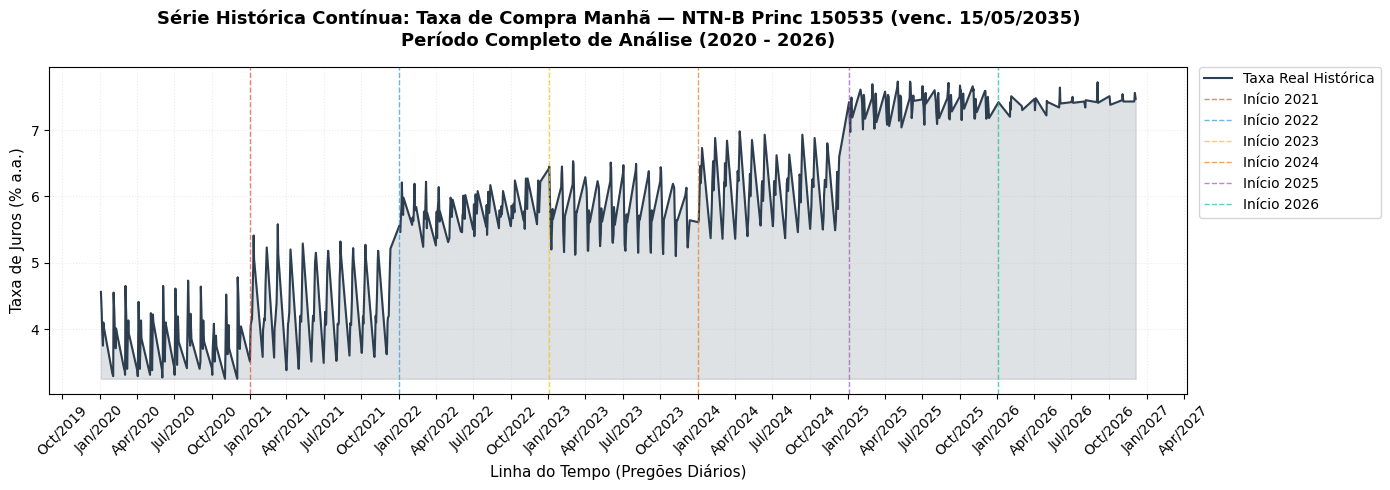

In [10]:
import matplotlib.dates as mdates

# ── Visualização da série completa (Adaptação Acadêmica para o TCC1) ──────
fig, ax = plt.subplots(figsize=(14, 5))

# Plotagem da Taxa Real Unificada (2020 a 2026) multiplicada por 100 para ficar em %
ax.plot(df_ipca['Data'], df_ipca['Taxa_Compra'] * 100, color='#2c3e50', lw=1.5, label='Taxa Real Histórica')
ax.fill_between(df_ipca['Data'], df_ipca['Taxa_Compra'] * 100,
                df_ipca['Taxa_Compra'].min() * 100, alpha=0.15, color='#2c3e50')

# Linhas de mudança de regime anual (Destaque para o início de cada ano civil)
cores_linhas = ['#e74c3c', '#3498db', '#f1c40f', '#e67e22', '#9b59b6', '#1abc9c']
anos_corte = [2021, 2022, 2023, 2024, 2025, 2026]

for ano, cor in zip(anos_corte, cores_linhas):
    # Localiza o primeiro pregão de cada ano para traçar a linha vertical de corte
    dias_ano = df_ipca[df_ipca['Data'].dt.year == ano]
    if not dias_ano.empty:
        corte = dias_ano['Data'].iloc[0]
        ax.axvline(corte, color=cor, ls='--', lw=1.0, alpha=0.7, label=f'Início {ano}')

# Formatação rigorosa dos eixos temporais (Escala de 3 em 3 meses para não poluir)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b/%Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)

# Títulos e Rótulos Acadêmicos
ABA_NOME = 'NTN-B Princ 150535'
ax.set_title(f'Série Histórica Contínua: Taxa de Compra Manhã — {ABA_NOME} (venc. 15/05/2035)\nPeríodo Completo de Análise (2020 - 2026)',
             fontweight='bold', fontsize=13, pad=15)
ax.set_ylabel('Taxa de Juros (% a.a.)', fontsize=11)
ax.set_xlabel('Linha do Tempo (Pregões Diários)', fontsize=11)

# Posicionamento da legenda fora do gráfico para não sobrepor as linhas
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), borderaxespad=0.)
ax.grid(alpha=0.25, linestyle=':')

plt.tight_layout()
plt.savefig('serie_completa_tesouro.png', dpi=300, bbox_inches='tight') # Salva em alta definição para o Word
plt.show()

# Boxplot Quartis

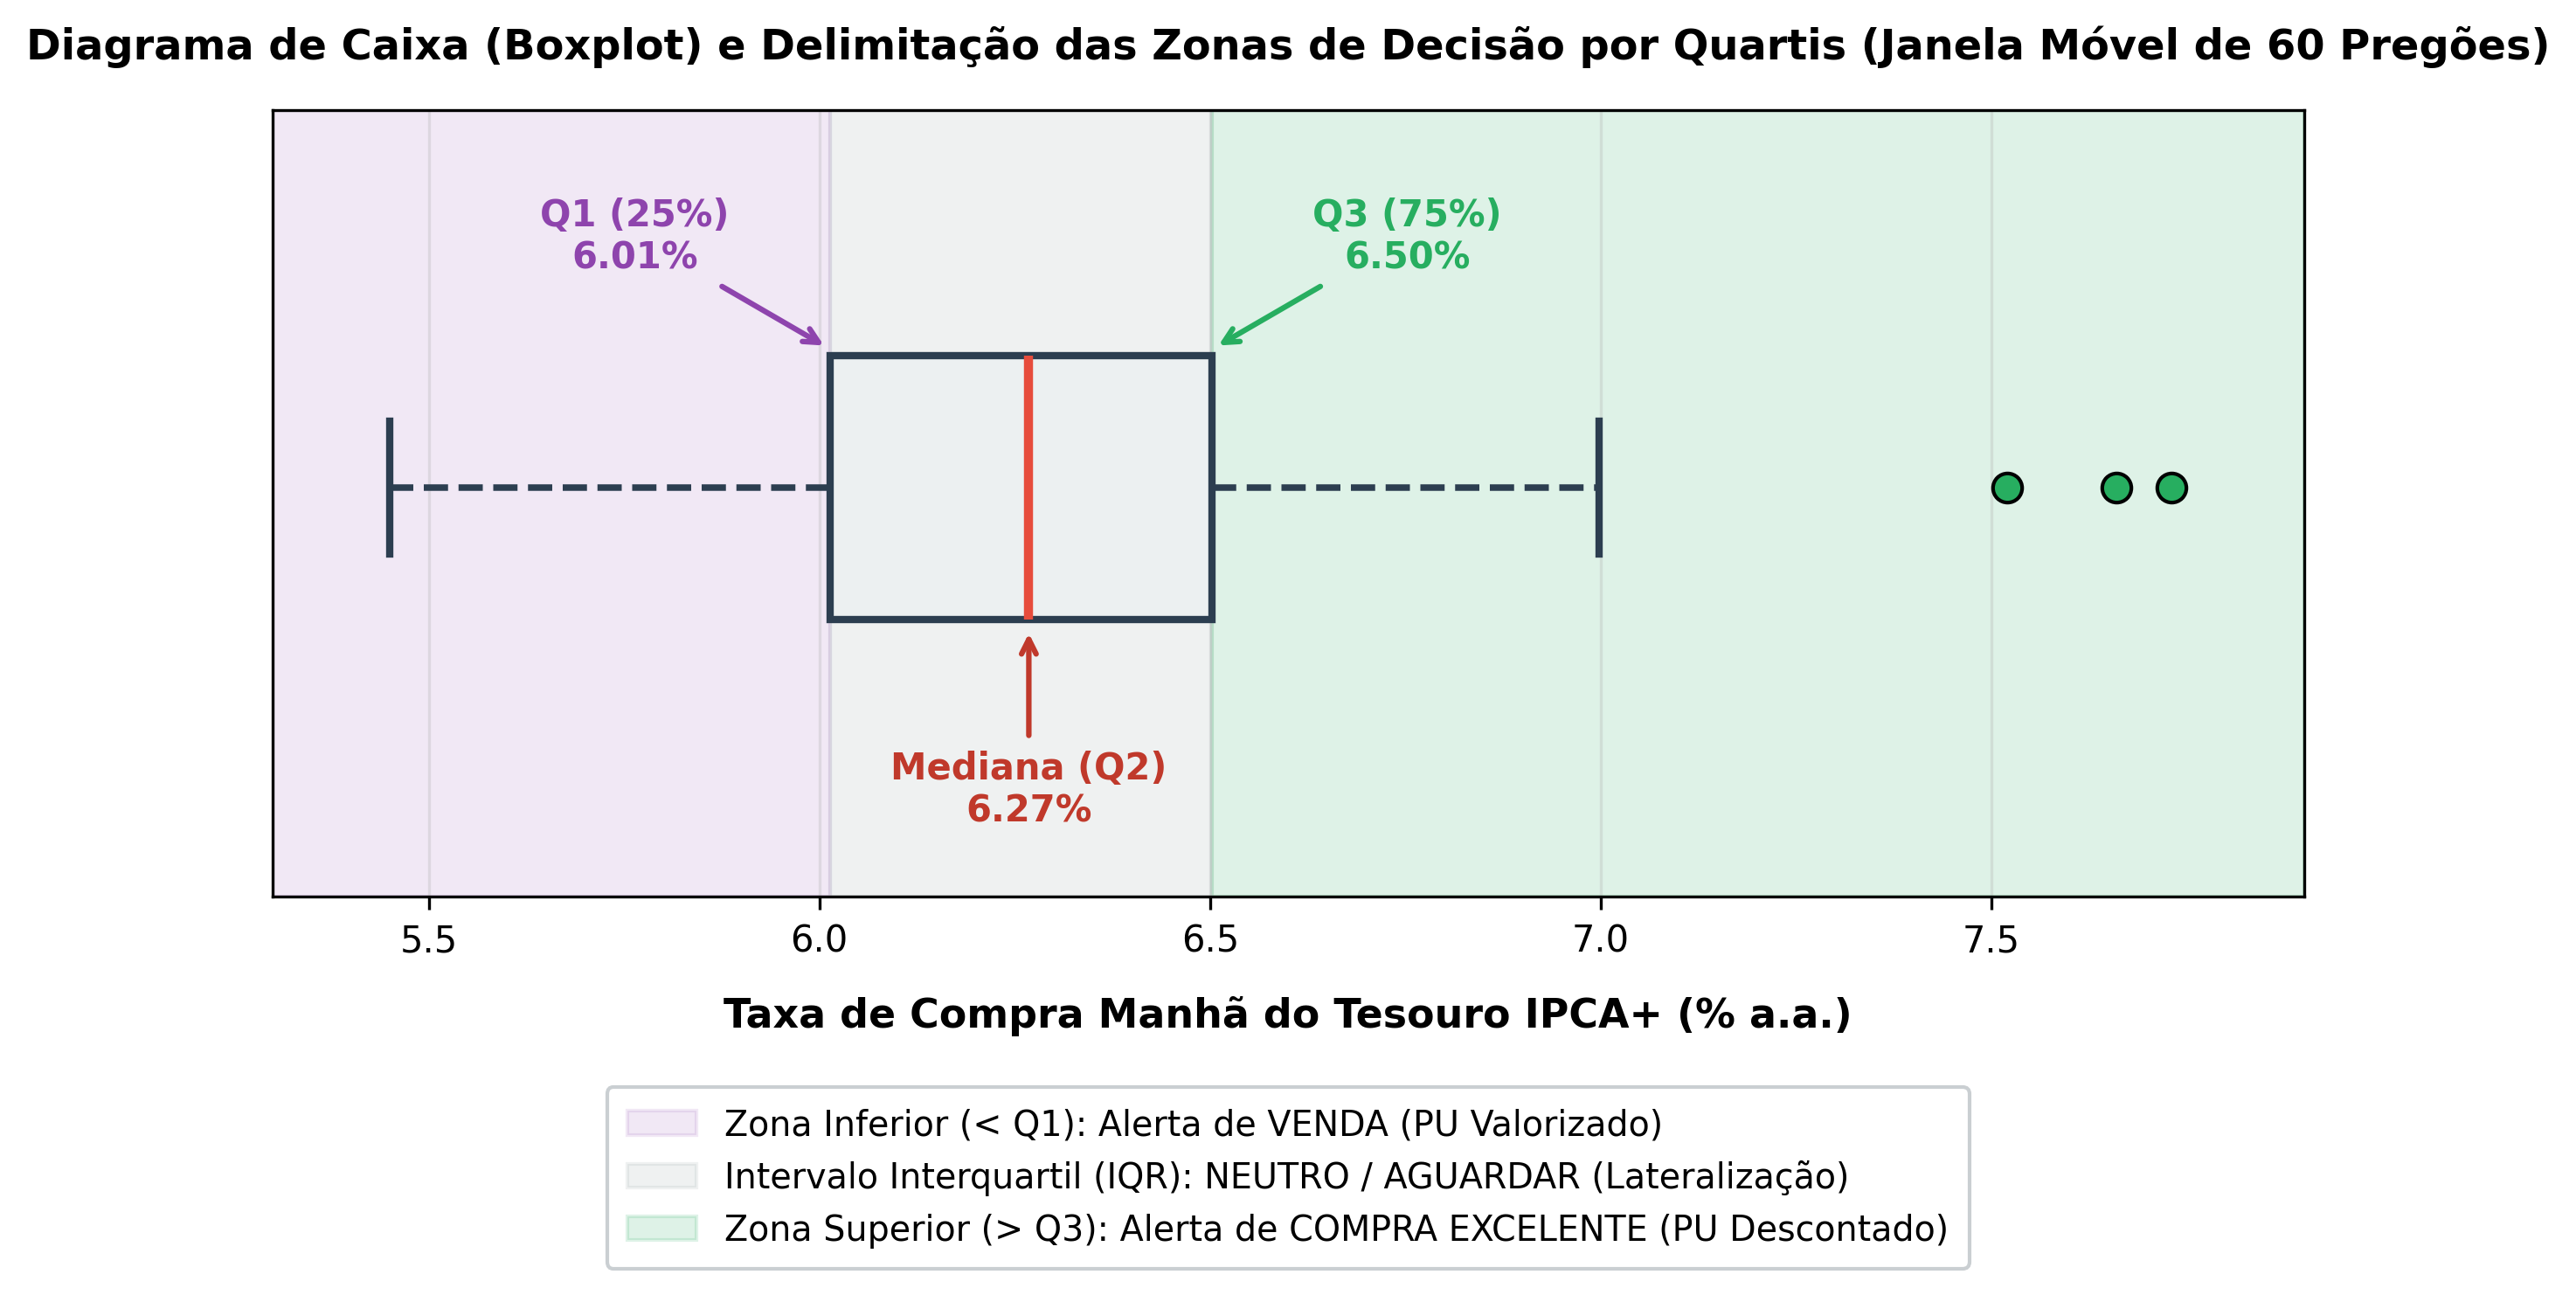

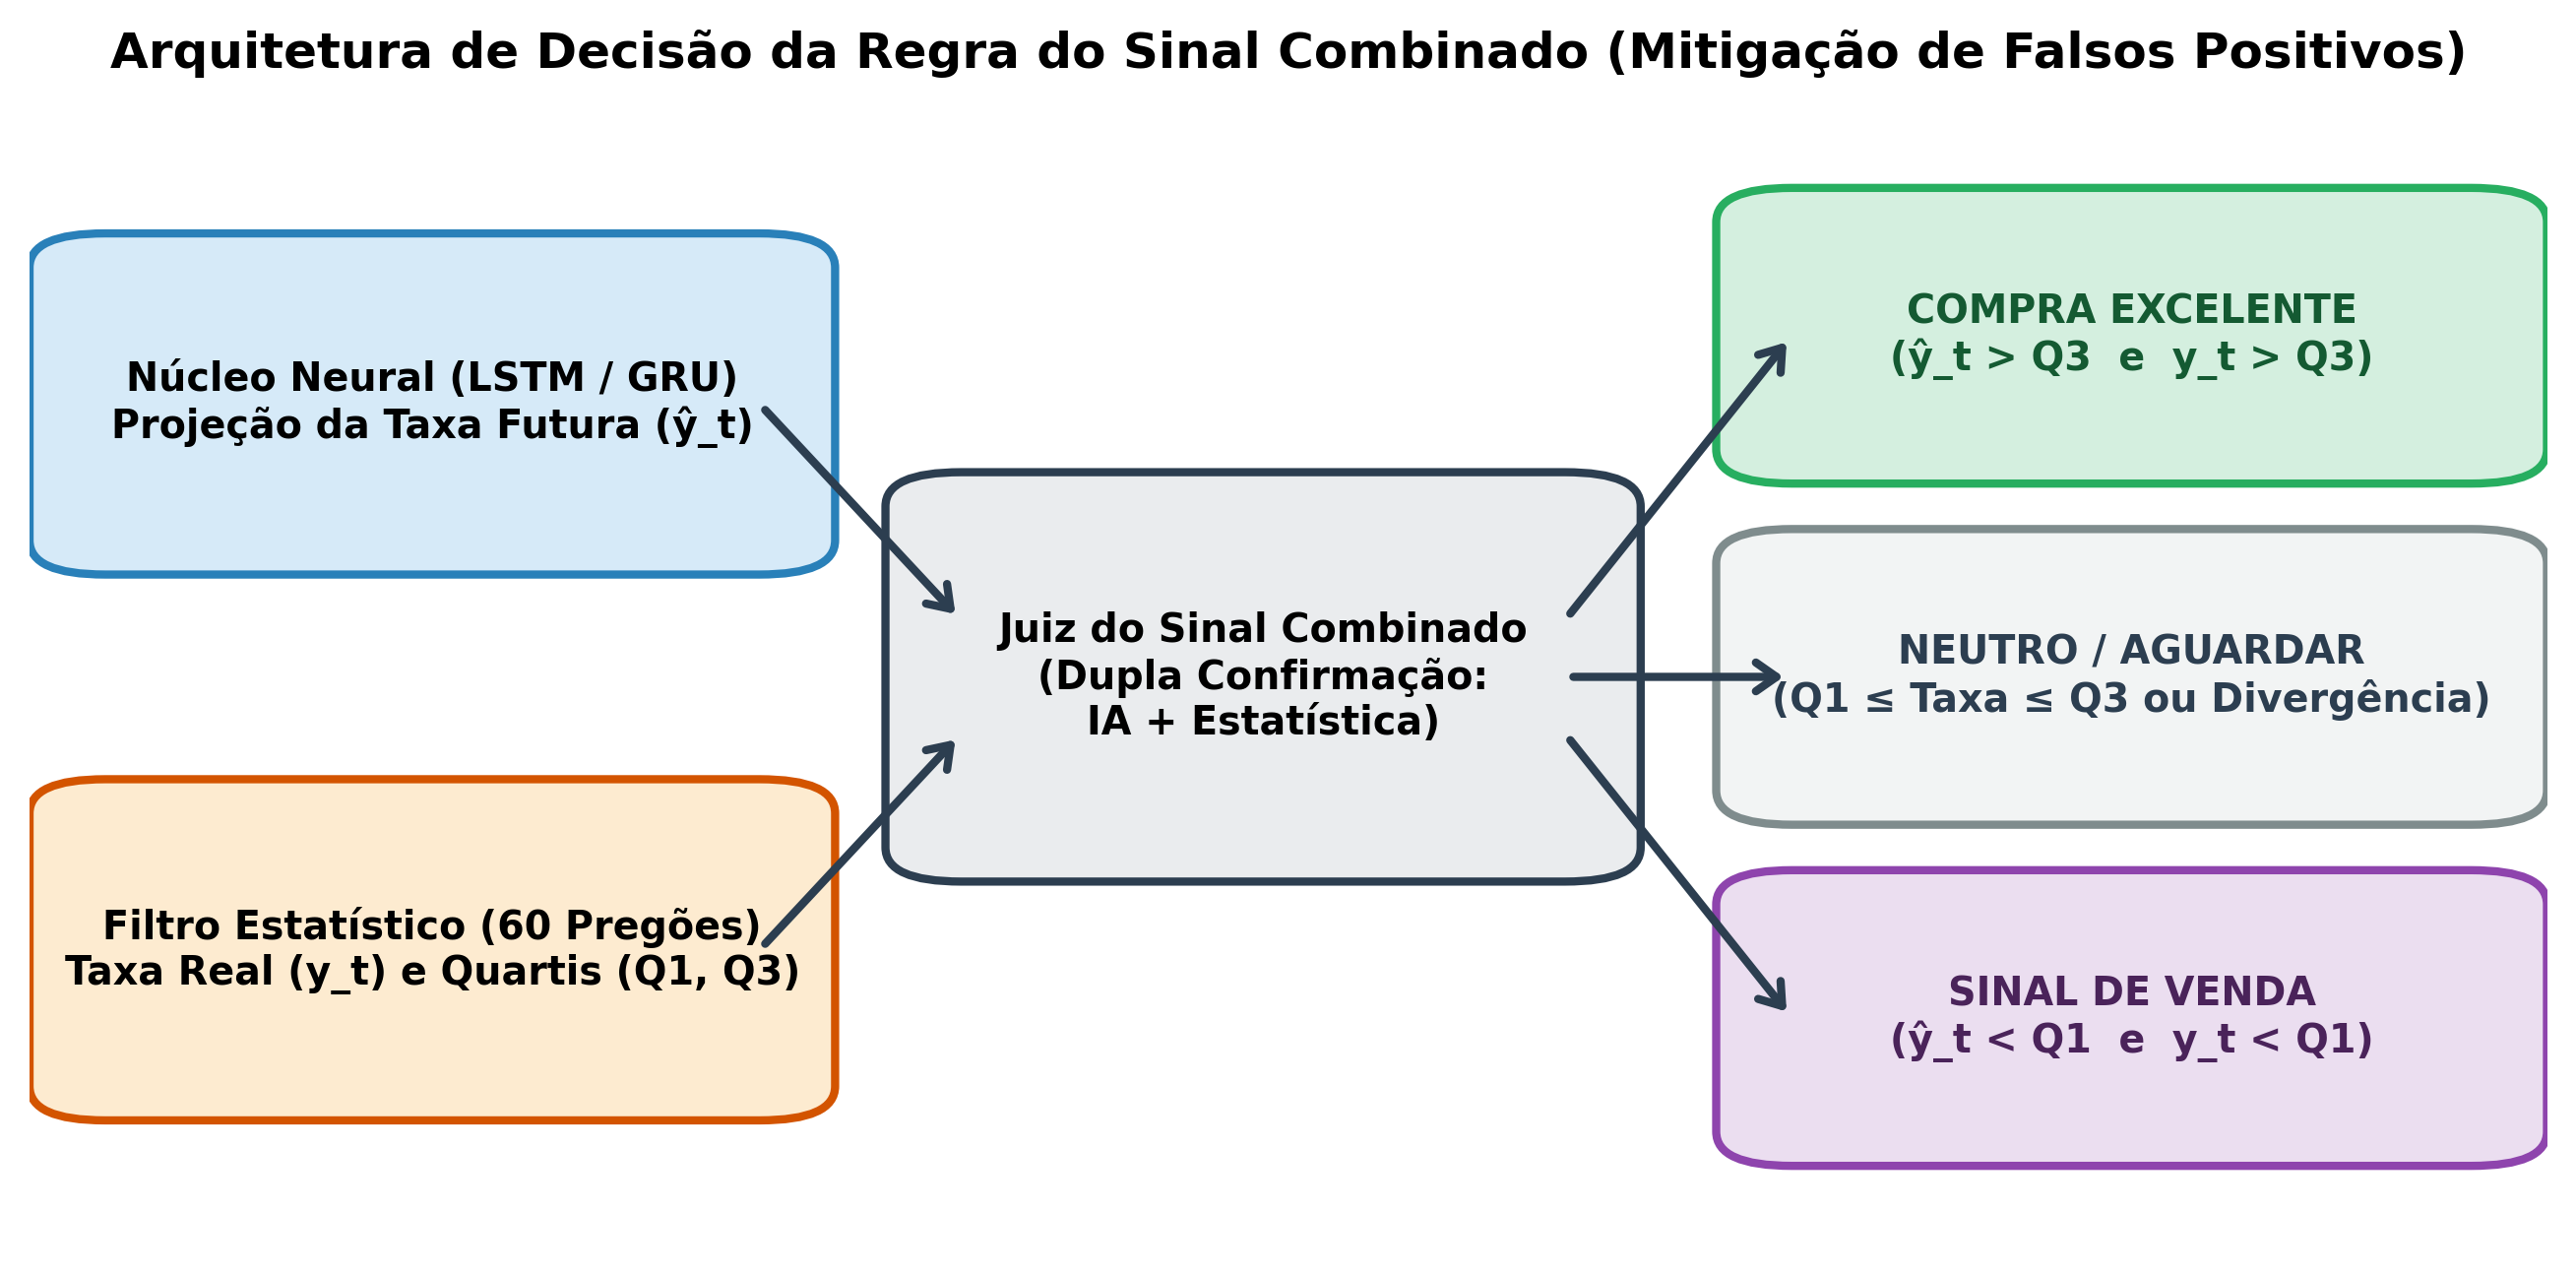

In [11]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# ==============================================================================
# FIGURA 1: BOXPLOT CONCEITUAL APLICADO ÀS TAXAS DO TESOURO IPCA+ (SEÇÃO 2.5)
# ==============================================================================
np.random.seed(42)
taxas_simuladas = np.concatenate([
    np.random.normal(6.35, 0.35, 50),  # Zona central (IQR)
    np.array([5.45, 5.55, 7.52, 7.66, 7.73])  # Extremos e anomalias
])

q1 = np.percentile(taxas_simuladas, 25)
mediana = np.percentile(taxas_simuladas, 50)
q3 = np.percentile(taxas_simuladas, 75)

fig, ax = plt.subplots(figsize=(10, 5.0), dpi=300)

# Zonas de Decisão Coloridas (zorder=1 mantém o fundo atrás do Boxplot)
ax.axvspan(5.3, q1, color='#8e44ad', alpha=0.12, zorder=1,
           label='Zona Inferior (< Q1): Alerta de VENDA (PU Valorizado)')
ax.axvspan(q1, q3, color='#95a5a6', alpha=0.15, zorder=1,
           label='Intervalo Interquartil (IQR): NEUTRO / AGUARDAR (Lateralização)')
ax.axvspan(q3, 7.9, color='#27ae60', alpha=0.15, zorder=1,
           label='Zona Superior (> Q3): Alerta de COMPRA EXCELENTE (PU Descontado)')

bp = ax.boxplot(
    taxas_simuladas, vert=False, patch_artist=True, widths=0.42, zorder=3,
    boxprops=dict(facecolor='#ecf0f1', edgecolor='#2c3e50', linewidth=2),
    medianprops=dict(color='#e74c3c', linewidth=2.5),
    whiskerprops=dict(color='#2c3e50', linewidth=1.8, linestyle='--'),
    capprops=dict(color='#2c3e50', linewidth=2),
    flierprops=dict(marker='o', markerfacecolor='#27ae60', markersize=8, markeredgecolor='black')
)

# Anotações Didáticas (Centralizadas sem sobrepor as bordas)
ax.annotate(f'Q1 (25%)\n{q1:.2f}%', xy=(q1, 1.22), xytext=(q1 - 0.25, 1.40),
            arrowprops=dict(arrowstyle='->', color='#8e44ad', lw=1.5),
            fontweight='bold', color='#8e44ad', ha='center', va='center')
ax.annotate(f'Mediana (Q2)\n{mediana:.2f}%', xy=(mediana, 0.78), xytext=(mediana, 0.52),
            arrowprops=dict(arrowstyle='->', color='#c0392b', lw=1.5),
            fontweight='bold', color='#c0392b', ha='center', va='center')
ax.annotate(f'Q3 (75%)\n{q3:.2f}%', xy=(q3, 1.22), xytext=(q3 + 0.25, 1.40),
            arrowprops=dict(arrowstyle='->', color='#27ae60', lw=1.5),
            fontweight='bold', color='#27ae60', ha='center', va='center')

ax.set_yticks([])
ax.set_xlim(5.3, 7.9)
ax.set_ylim(0.35, 1.60)
ax.set_xlabel('Taxa de Compra Manhã do Tesouro IPCA+ (% a.a.)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_title('Diagrama de Caixa (Boxplot) e Delimitação das Zonas de Decisão por Quartis (Janela Móvel de 60 Pregões)',
             fontsize=11.5, fontweight='bold', pad=14)

# CORREÇÃO: loc='upper center' ancora o TOPO da legenda em y = -0.22 (abaixo do xlabel),
# fazendo a caixa crescer para baixo sem jamais cobrir o título do eixo X.
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=1,
          frameon=True, facecolor='white', edgecolor='#bdc3c7', fontsize=9.5, borderpad=0.6)

ax.grid(axis='x', alpha=0.3, zorder=0)
plt.subplots_adjust(bottom=0.28)
plt.savefig('Figura_1_Boxplot_Quartis.png', dpi=300, bbox_inches='tight', pad_inches=0.15)
plt.show()

# ==============================================================================
# FIGURA 2: ARQUITETURA DE DECISÃO DA REGRA DO SINAL COMBINADO (SEÇÃO 2.5)
# ==============================================================================
fig, ax = plt.subplots(figsize=(11, 5), dpi=300)
ax.axis('off')

def draw_box(ax, x, y, w, h, text, bg_color, border_color='#2c3e50', text_color='black'):
    rect = patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03",
                                  facecolor=bg_color, edgecolor=border_color, linewidth=2)
    ax.add_patch(rect)
    ax.text(x + w/2, y + h/2, text, ha='center', va='center', fontsize=9.5,
            fontweight='bold', color=text_color)

# Caixas de Entrada
draw_box(ax, 0.03, 0.62, 0.26, 0.24, "Núcleo Neural (LSTM / GRU)\nProjeção da Taxa Futura (ŷ_t)", "#d6eaf8", "#2980b9")
draw_box(ax, 0.03, 0.14, 0.26, 0.24, "Filtro Estatístico (60 Pregões)\nTaxa Real (y_t) e Quartis (Q1, Q3)", "#fdebd0", "#d35400")

# Caixa Central (Juiz / Convergência)
draw_box(ax, 0.37, 0.35, 0.24, 0.30, "Juiz do Sinal Combinado\n(Dupla Confirmação:\nIA + Estatística)", "#eaecee", "#2c3e50")

# Caixas de Saída (Sinais)
draw_box(ax, 0.70, 0.70, 0.27, 0.20, "COMPRA EXCELENTE\n(ŷ_t > Q3  e  y_t > Q3)", "#d4efdf", "#27ae60", "#145a32")
draw_box(ax, 0.70, 0.40, 0.27, 0.20, "NEUTRO / AGUARDAR\n(Q1 ≤ Taxa ≤ Q3 ou Divergência)", "#f2f4f4", "#7f8c8d", "#2c3e50")
draw_box(ax, 0.70, 0.10, 0.27, 0.20, "SINAL DE VENDA\n(ŷ_t < Q1  e  y_t < Q1)", "#ebdef0", "#8e44ad", "#4a235a")

# Setas de Conexão
arrow_style = dict(arrowstyle="->,head_width=0.35,head_length=0.5", color="#2c3e50", lw=2)
ax.annotate("", xy=(0.37, 0.55), xytext=(0.29, 0.74), arrowprops=arrow_style)
ax.annotate("", xy=(0.37, 0.45), xytext=(0.29, 0.26), arrowprops=arrow_style)
ax.annotate("", xy=(0.70, 0.80), xytext=(0.61, 0.55), arrowprops=arrow_style)
ax.annotate("", xy=(0.70, 0.50), xytext=(0.61, 0.50), arrowprops=arrow_style)
ax.annotate("", xy=(0.70, 0.20), xytext=(0.61, 0.45), arrowprops=arrow_style)

ax.set_title("Arquitetura de Decisão da Regra do Sinal Combinado (Mitigação de Falsos Positivos)",
             fontsize=12, fontweight='bold', pad=10)
plt.savefig('Figura_2_Fluxograma_Sinal_Combinado.png', dpi=300, bbox_inches='tight', pad_inches=0.15)
plt.show()

# Novo Gráfico da Seção 4.2

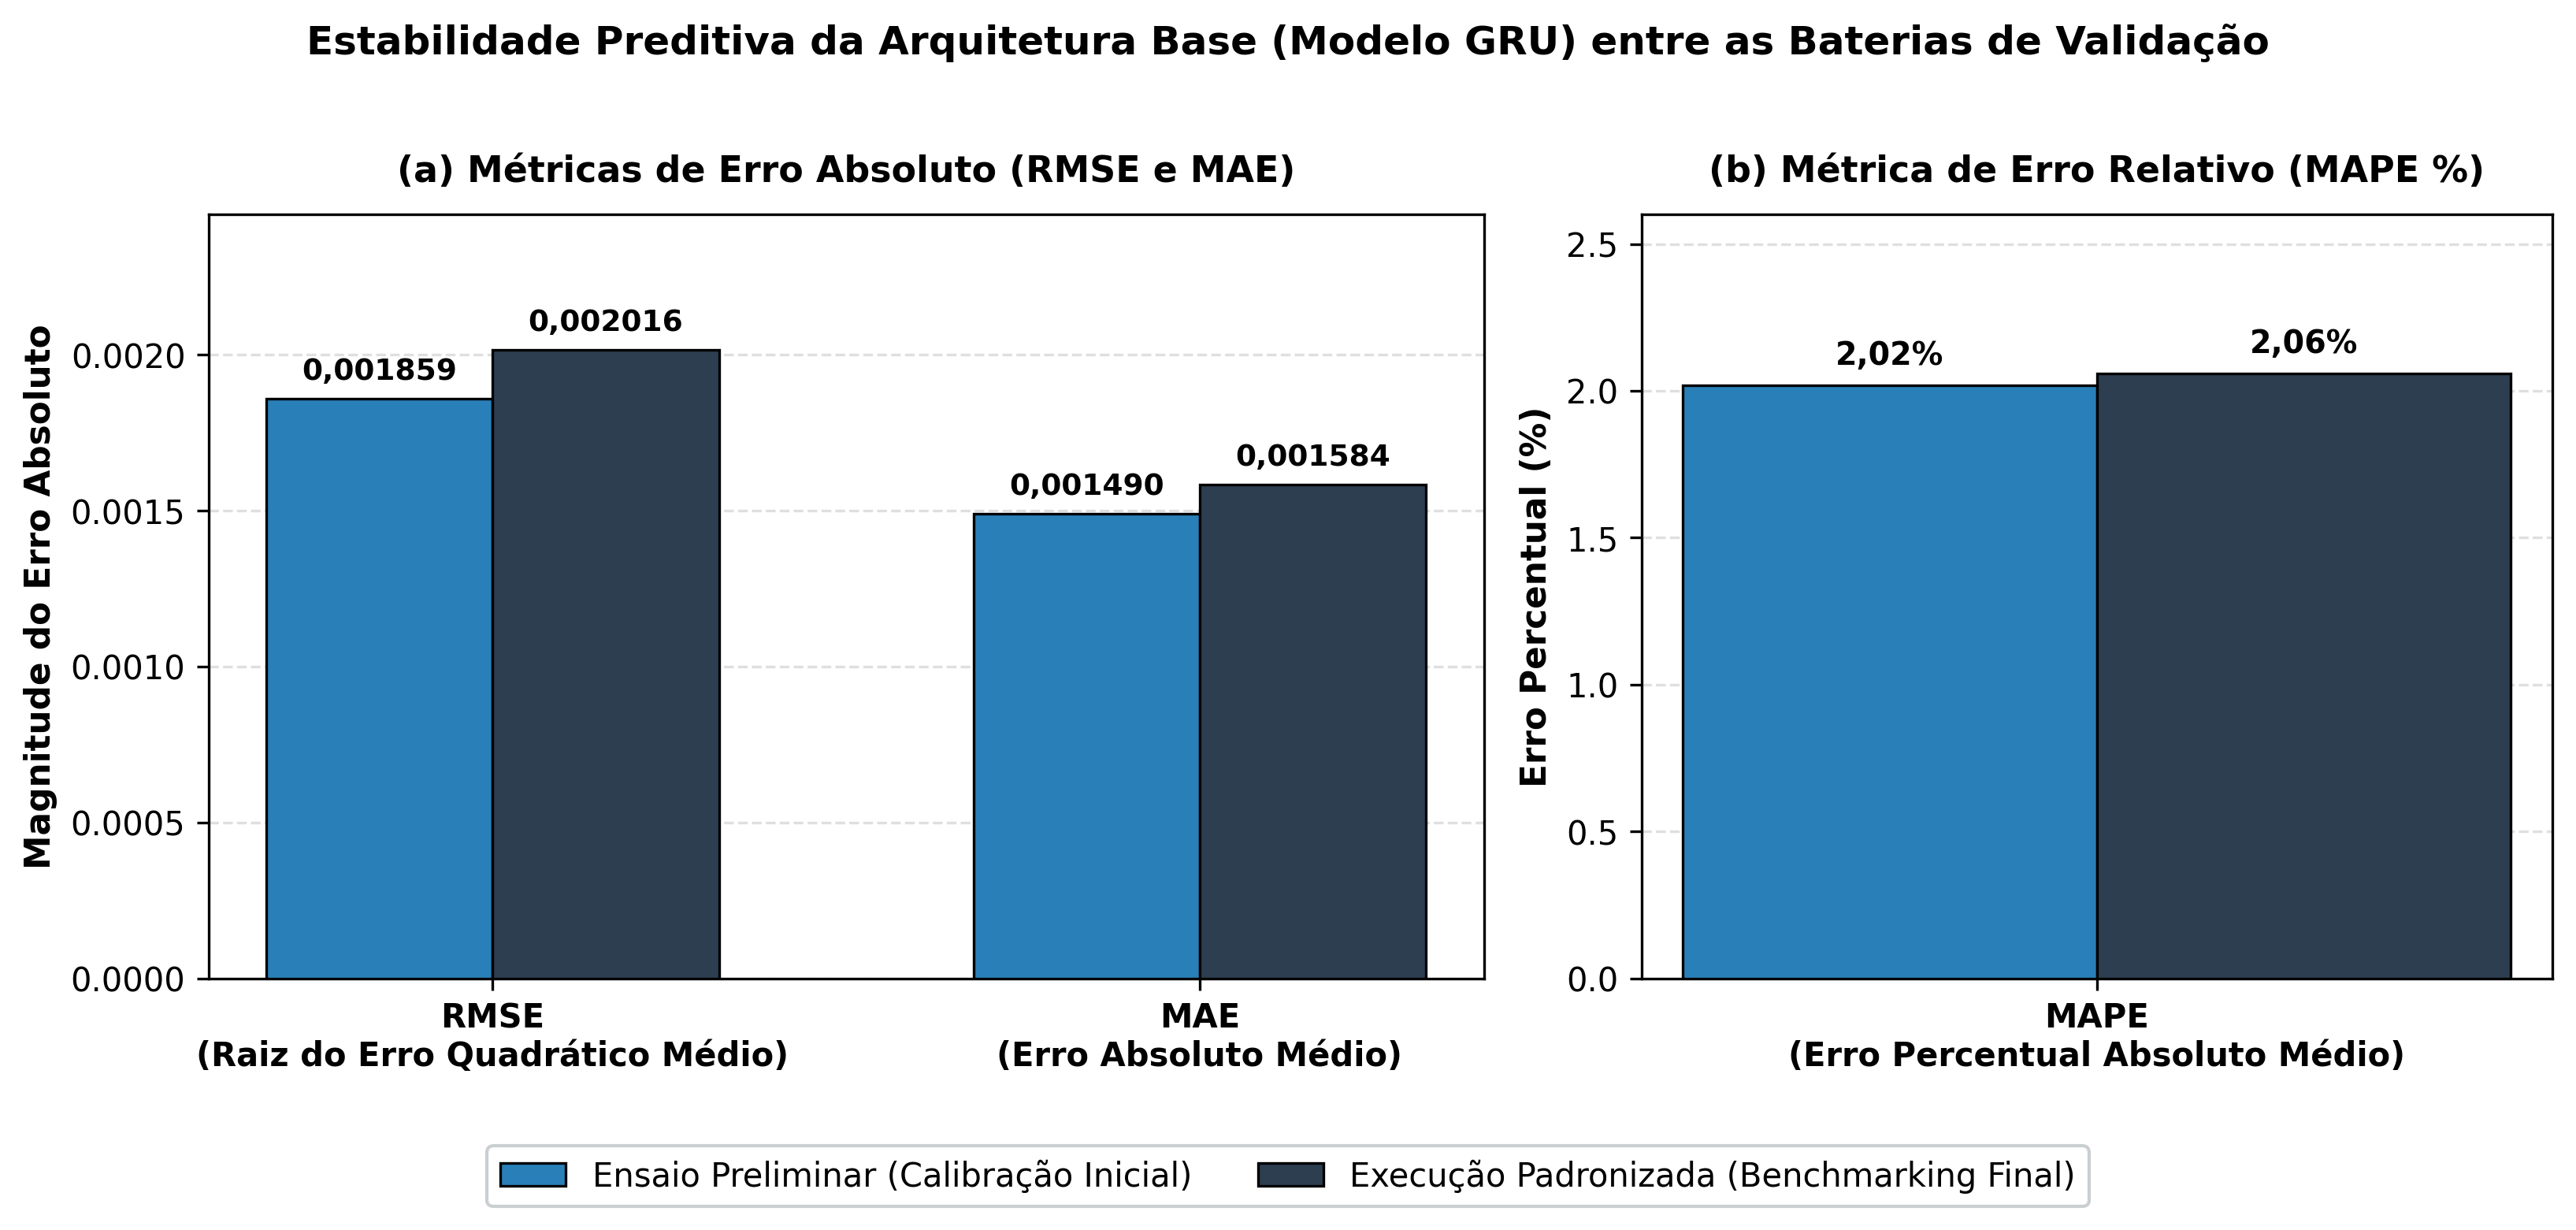

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# FIGURA 6: GRÁFICO COMPARATIVO DE DESEMPENHO DO MODELO BASE (GRU) - SEÇÃO 4.2
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=300, gridspec_kw={'width_ratios': [1.4, 1]})

cor_preliminar = '#2980b9'   # Azul acadêmico
cor_padronizada = '#2c3e50'  # Cinza-azulado escuro

# --- Painel (a): Métricas Absolutas (RMSE e MAE) ---
metricas_abs = ['RMSE\n(Raiz do Erro Quadrático Médio)', 'MAE\n(Erro Absoluto Médio)']
val_preliminar = [0.001859, 0.001490]
val_padronizada = [0.002016, 0.001584]

x = np.arange(len(metricas_abs))
largura = 0.32

rects1 = ax1.bar(x - largura/2, val_preliminar, largura, label='Ensaio Preliminar (Calibração Inicial)',
                 color=cor_preliminar, edgecolor='black', linewidth=0.8, zorder=3)
rects2 = ax1.bar(x + largura/2, val_padronizada, largura, label='Execução Padronizada (Benchmarking Final)',
                 color=cor_padronizada, edgecolor='black', linewidth=0.8, zorder=3)

ax1.set_ylabel('Magnitude do Erro Absoluto', fontsize=10.5, fontweight='bold')
ax1.set_title('(a) Métricas de Erro Absoluto (RMSE e MAE)', fontsize=11, fontweight='bold', pad=10)
ax1.set_xticks(x)
ax1.set_xticklabels(metricas_abs, fontsize=10, fontweight='bold')
ax1.set_ylim(0, 0.00245)
ax1.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)

# Rótulos de dados no topo das barras (Painel a)
for rect in rects1 + rects2:
    altura = rect.get_height()
    ax1.annotate(f'{altura:.6f}'.replace('.', ','),
                 xy=(rect.get_x() + rect.get_width() / 2, altura),
                 xytext=(0, 4), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# --- Painel (b): Métrica Relativa Percentual (MAPE) ---
metricas_rel = ['MAPE\n(Erro Percentual Absoluto Médio)']
mape_preliminar = [2.02]
mape_padronizada = [2.06]

x_rel = np.arange(len(metricas_rel))
rects3 = ax2.bar(x_rel - largura/2, mape_preliminar, largura, label='Ensaio Preliminar (Calibração Inicial)',
                 color=cor_preliminar, edgecolor='black', linewidth=0.8, zorder=3)
rects4 = ax2.bar(x_rel + largura/2, mape_padronizada, largura, label='Execução Padronizada (Benchmarking Final)',
                 color=cor_padronizada, edgecolor='black', linewidth=0.8, zorder=3)

ax2.set_ylabel('Erro Percentual (%)', fontsize=10.5, fontweight='bold')
ax2.set_title('(b) Métrica de Erro Relativo (MAPE %)', fontsize=11, fontweight='bold', pad=10)
ax2.set_xticks(x_rel)
ax2.set_xticklabels(metricas_rel, fontsize=10, fontweight='bold')
ax2.set_ylim(0, 2.6)
ax2.grid(axis='y', linestyle='--', alpha=0.4, zorder=0)

# Rótulos de dados no topo das barras (Painel b)
for rect in rects3 + rects4:
    altura = rect.get_height()
    ax2.annotate(f'{altura:.2f}%'.replace('.', ','),
                 xy=(rect.get_x() + rect.get_width() / 2, altura),
                 xytext=(0, 4), textcoords="offset points",
                 ha='center', va='bottom', fontsize=9.5, fontweight='bold')

# Título Geral e Legenda Unificada na Base
fig.suptitle('Estabilidade Preditiva da Arquitetura Base (Modelo GRU) entre as Baterias de Validação',
             fontsize=12, fontweight='bold', y=1.02)

handles, labels = ax1.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02),
           ncol=2, frameon=True, facecolor='white', edgecolor='#bdc3c7', fontsize=10)

plt.tight_layout()
plt.savefig('Figura_6_Desempenho_GRU.png', dpi=300, bbox_inches='tight', pad_inches=0.15)
plt.show()